# Lista 1 - Wstęp do uczenia maszynowego

## Zadanie 1

Instalacja i konfiguracja środowiska: Utwórz wirtualne środowisko dla kursu. Zainstaluj niezbędne biblioteki: pandas, numpy, scikit-learn, matplotlib.

## Zadanie 2
Wczytanie i eksploracja danych: Wczytaj publicznie dostępny zbiór danych Iris z biblioteki scikit-learn lub bezpośrednio z adresu URL. Wyświetl pierwsze kilka wierszy i podstawowe informacje o zbiorze (`df.info()`, `df.describe()`).

In [1]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = load_iris(as_frame=True).frame
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Zadanie 3
Obsługa brakujących wartości: Wczytaj zbiór danych Titanic (dostępny na Kaggle). Sprawdź, które kolumny zawierają brakujące wartości. Zaproponuj i zaimplementuj dwie różne strategie ich uzupełniania.

In [5]:
gender_submission = pd.read_csv('titanic/gender_submission.csv')
train = pd.read_csv('titanic/train.csv')
test = pd.read_csv('titanic/test.csv')

display(gender_submission.head())
display(train.head())
display(test.head())

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [6]:
print('gender submission shape: ', gender_submission.shape)
print('train shape: ', train.shape)
print('test shape: ', test.shape)

gender submission shape:  (418, 2)
train shape:  (891, 12)
test shape:  (418, 11)


In [7]:
# Sprawdzenie brakujących wartości w zbiorach danych
print(gender_submission.isna().sum())

PassengerId    0
Survived       0
dtype: int64


In [8]:
print(train.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [9]:
print(test.isna().sum())

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


### Strategia uzupełniania braków danych

1. Uzupełnianie braków danych najczęściej występującą wartością (modą) - dla kolumn kategorycznych.
2. Uzupełnianie braków danych średnią arytmetyczną lub medianą - dla kolumn numerycznych.
3. Uzupełnianie braków danych wartością stałą (np. "Undefined" lub 0).
4. Pomijanie wierszy z brakami danych.
5. Pomijanie kolumn z brakami danych.

In [10]:
def fill_na_with_mode(dataframe, columns):
    if isinstance(columns, str):
        columns = [columns]
    for column in columns:
        most_common = dataframe[column].mode()[0]           # Uzupełnianie braków danych najczęściej występującą wartością
        dataframe[column] = dataframe[column].fillna(most_common)
    return dataframe


def fill_na_with_mean(dataframe, columns):
    if isinstance(columns, str):
        columns = [columns]
    for column in columns:
        try:
            mean_value = dataframe[column].mean()           # Uzupełnianie braków danych średnią arytmetyczną
            dataframe[column] = dataframe[column].fillna(mean_value)
        except ValueError:
            print(f'Column {column} is not numeric, cannot fill with mean.')
    return dataframe


def fill_na_with_median(dataframe, columns):
    if isinstance(columns, str):
        columns = [columns]
    for column in columns:
        try:
            median_value = dataframe[column].median()       # Uzupełnianie braków danych medianą
            dataframe[column] = dataframe[column].fillna(median_value)
        except ValueError:
            print(f'Column {column} is not numeric, cannot fill with median.')
    return dataframe


def fill_na_with_constant(dataframe, columns, constant_value="Undefined"):
    if isinstance(columns, str):
        columns = [columns]
    for column in columns:
        dataframe[column] = dataframe[column].fillna(constant_value)  # Uzupełnianie braków danych wartością stałą
    return dataframe


def skipping_na_rows(dataframe, columns):
    if isinstance(columns, str):
        columns = [columns]
    return dataframe.dropna(subset=columns)                 # Pomijanie wierszy z brakami danych


def skipping_na_columns(dataframe, columns):
    if isinstance(columns, str):
        columns = [columns]
    return dataframe.drop(columns=columns)                   # Pomijanie kolumn z brakami danych

In [11]:
# Przykładowe użycie funkcji do uzupełniania braków danych w zbiorze train

train = skipping_na_rows(train, columns='Embarked')   # - usunięcie wierszy z brakami danych w kolumnie 'Embarked'
train = fill_na_with_mean(train, columns='Age')       # - uzupełnienie braków danych w kolumnie 'Age' średnią arytmetyczną
train = skipping_na_columns(train, columns='Cabin')   # - usunięcie kolumny 'Cabin', ponieważ ma dużo braków danych

print(train.isna().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [12]:
# Przykładowe użycie funkcji do uzupełniania braków danych w zbiorze test

test = skipping_na_columns(test, columns='Cabin')    # - usunięcie kolumny 'Cabin', ponieważ ma dużo braków danych
test = fill_na_with_median(test, columns='Age')      # - uzupełnienie braków danych w kolumnie 'Age' medianą
test = fill_na_with_constant(test, columns='Fare')   # - uzupełnienie braków danych w kolumnie 'Fare' wartością "Undefined"

print(test.isna().sum())

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## Zadanie 4

Przetwarzanie danych kategorialnych: Wykorzystaj kolumny kategorialne (np. płeć, port zaokrętowania) ze zbioru Titanic. Przekształć je na format numeryczny, używając techniki One-Hot Encoding z biblioteki pandas (`pd.get dummies()`) oraz scikit-learn.

In [13]:
pd.get_dummies(
    train,
    columns=['Sex', 'Embarked'],
    prefix=['Sex', 'Emb'],
    # dummy_na = True, # Dodaje kolumnę dla brakujących wartości
    dtype=int
).head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Emb_C,Emb_Q,Emb_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,1,0,0,1


In [14]:
from sklearn.preprocessing import OneHotEncoder


data = train[['Sex', 'Embarked']]

enc = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore',
    categories='auto',
    dtype=int
)

enc.fit(data)

names = enc.get_feature_names_out()
x = enc.transform(data)

transformed_dataframe = pd.DataFrame(x, columns=names)
transformed_dataframe.head()

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,1,0,0,1
1,1,0,1,0,0
2,1,0,0,0,1
3,1,0,0,0,1
4,0,1,0,0,1


## Zadanie 5

Skalowanie danych numerycznych: Wybierz kolumny numeryczne ze zbioru Iris (np. długość i szerokość płatka). Zastosuj dwie różne metody skalowania:
 - Standaryzacja (StandardScaler): Przekształć dane tak, aby
miały średnią 0 i odchylenie standardowe 1.
 -  Normalizacja (MinMaxScaler): Przekształć dane tak, aby ich
wartości mieściły się w zakresie od 0 do 1.

Zwizualizuj dane przed i po skalowaniu za pomocą wykresu punktowego.

In [15]:
iris_df = load_iris(as_frame=True).frame

In [16]:
def standard_scaler_manual(dataframe, columns):
    new_dataframe = dataframe.copy()
    if isinstance(columns, str):
        columns = [columns]
    for column in columns:
        mean = dataframe[column].mean()
        std = dataframe[column].std(ddof=0)  # Parametr definiuje rodzaj odchylenia standardowego
        new_dataframe[column] = (dataframe[column] - mean) / std
    return new_dataframe

In [17]:
normalized_data = standard_scaler_manual(iris_df.copy(), columns=['sepal length (cm)', 'sepal width (cm)'])
normalized_data[['sepal length (cm)', 'sepal width (cm)']].describe()

,sepal length (cm),sepal width (cm)
count,1.500000e+02,1.500000e+02
mean,-4.736952e-16,-7.815970e-16
std,1.003350e+00,1.003350e+00
min,-1.870024e+00,-2.433947e+00
25%,-9.006812e-01,-5.923730e-01
50%,-5.250608e-02,-1.319795e-01
75%,6.745011e-01,5.586108e-01
max,2.492019e+00,3.090775e+00


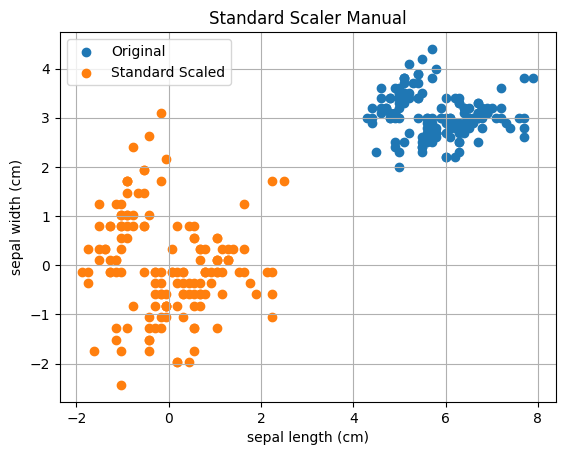

In [18]:
plt.scatter(iris_df['sepal length (cm)'], iris_df['sepal width (cm)'])
plt.scatter(normalized_data['sepal length (cm)'], normalized_data['sepal width (cm)'])
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Standard Scaler Manual')
plt.legend(['Original', 'Standard Scaled'])
plt.grid(True)
plt.show()

In [19]:
scaler = StandardScaler()
scaler.fit(iris_df[['sepal length (cm)', 'sepal width (cm)']].dropna())
sklearn_scaled = iris_df.copy()
sklearn_scaled[['sepal length (cm)', 'sepal width (cm)']] = scaler.transform(iris_df[['sepal length (cm)', 'sepal width (cm)']])

sklearn_scaled[['sepal length (cm)', 'sepal width (cm)']].describe()

,sepal length (cm),sepal width (cm)
count,1.500000e+02,1.500000e+02
mean,-4.736952e-16,-7.815970e-16
std,1.003350e+00,1.003350e+00
min,-1.870024e+00,-2.433947e+00
25%,-9.006812e-01,-5.923730e-01
50%,-5.250608e-02,-1.319795e-01
75%,6.745011e-01,5.586108e-01
max,2.492019e+00,3.090775e+00


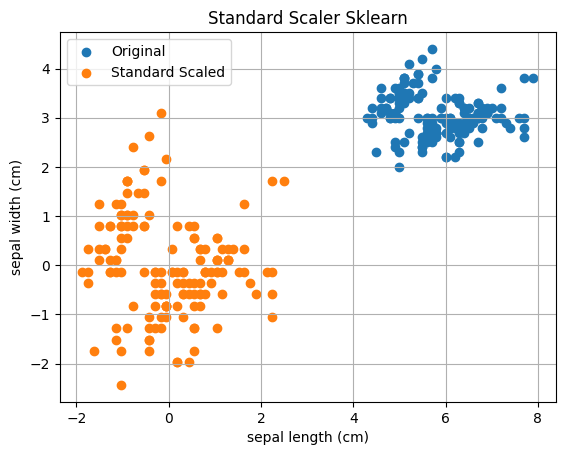

In [20]:
plt.scatter(iris_df['sepal length (cm)'], iris_df['sepal width (cm)'])
plt.scatter(sklearn_scaled['sepal length (cm)'], sklearn_scaled['sepal width (cm)'])
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Standard Scaler Sklearn')
plt.legend(['Original', 'Standard Scaled'])
plt.grid(True)
plt.show()

In [21]:
def min_max_scaler_manual(dataframe, columns):
    new_dataframe = dataframe.copy()
    if isinstance(columns, str):
        columns = [columns]
    for column in columns:
        min_value = dataframe[column].min()
        max_value = dataframe[column].max()
        new_dataframe[column] = (dataframe[column] - min_value) / (max_value - min_value)
    return new_dataframe

In [22]:
min_max_normalized = min_max_scaler_manual(iris_df.copy(), columns=['sepal length (cm)', 'sepal width (cm)'])
min_max_normalized[['sepal length (cm)', 'sepal width (cm)']].describe()

,sepal length (cm),sepal width (cm)
count,150.000000,150.000000
mean,0.428704,0.440556
std,0.230018,0.181611
min,0.000000,0.000000
25%,0.222222,0.333333
50%,0.416667,0.416667
75%,0.583333,0.541667
max,1.000000,1.000000


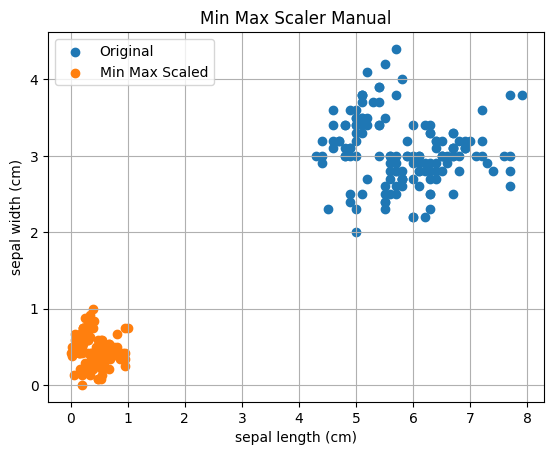

In [23]:
plt.scatter(iris_df['sepal length (cm)'], iris_df['sepal width (cm)'])
plt.scatter(min_max_normalized['sepal length (cm)'], min_max_normalized['sepal width (cm)'])
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Min Max Scaler Manual')
plt.legend(['Original', 'Min Max Scaled'])
plt.grid(True)
plt.show()

In [24]:
scaler = MinMaxScaler()
scaler.fit(iris_df[['sepal length (cm)', 'sepal width (cm)']].dropna())
min_max_sklearn_scaled = iris_df.copy()
min_max_sklearn_scaled[['sepal length (cm)', 'sepal width (cm)']] = scaler.transform(iris_df[['sepal length (cm)', 'sepal width (cm)']])

min_max_sklearn_scaled[['sepal length (cm)', 'sepal width (cm)']].describe()

,sepal length (cm),sepal width (cm)
count,150.000000,150.000000
mean,0.428704,0.440556
std,0.230018,0.181611
min,0.000000,0.000000
25%,0.222222,0.333333
50%,0.416667,0.416667
75%,0.583333,0.541667
max,1.000000,1.000000


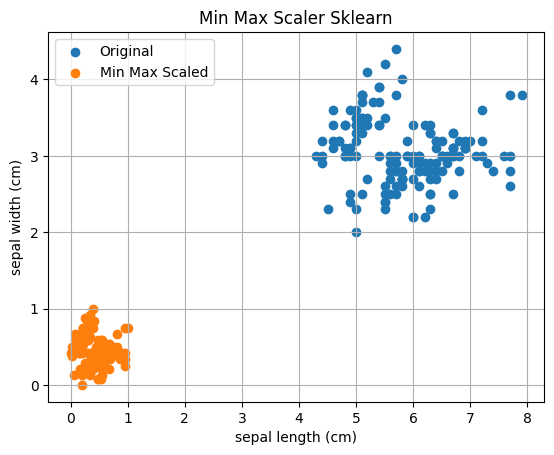

In [25]:
plt.scatter(iris_df['sepal length (cm)'], iris_df['sepal width (cm)'])
plt.scatter(min_max_sklearn_scaled['sepal length (cm)'], min_max_sklearn_scaled['sepal width (cm)'])
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.title('Min Max Scaler Sklearn')
plt.legend(['Original', 'Min Max Scaled'])
plt.grid(True)
plt.show()

## Zadanie 6

Podział zbioru danych: Dokonaj podziału zbioru Iris na zbiór treningowy (70%) i testowy (30%) za pomocą funkcji train test split
z biblioteki scikit-learn. Sprawdź wymiary powstałych zbiorów.

In [26]:
from sklearn.model_selection import train_test_split


df = load_iris(as_frame=True).frame

train_x, test_x, train_y, test_y = train_test_split(
    df.drop(columns='target'),
    df['target'],
    test_size=0.3,
    # random_state=7
)

print('train_x shape: ', train_x.shape)
print('train_y shape: ', train_y.shape)
print('test_x shape: ', test_x.shape)
print('test_y shape: ', test_y.shape)

train_x shape:  (105, 4)
train_y shape:  (105,)
test_x shape:  (45, 4)
test_y shape:  (45,)


## Zadanie 7

Przygotowanie danych do modelowania: Wybierz dowolny zbiór danych i przeprowadź pełny proces przygotowania danych: wczytanie, obsługa brakujących wartości, przetwarzanie danych kategorialnych i skalowanie danych numerycznych. Zapisz przygotowany zbiór do pliku.

Użyte dane: https://www.kaggle.com/datasets/wardabilal/salary-prediction-dataset 

In [27]:
salary_df = pd.read_csv('Salary_Data.csv')
display(salary_df.head())

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [28]:
salary_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [29]:
print(salary_df.isna().sum())
salary_df['Age'][salary_df['Age'].isna()]

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64


172   NaN
260   NaN
Name: Age, dtype: float64

In [30]:
salary_df = fill_na_with_mode(salary_df, columns=['Gender', 'Education Level', 'Job Title'])
salary_df = fill_na_with_mean(salary_df, columns=['Age', 'Years of Experience', 'Salary'])

In [31]:
print(salary_df.isna().sum())

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


In [32]:
salary_df = pd.get_dummies(
    salary_df,
    columns=['Gender', 'Education Level', 'Job Title'],
    dtype=int
)

display(salary_df.head())

,Age,Years of Experience,Salary,Gender_Female,Gender_Male,Gender_Other,Education Level_Bachelor's,Education Level_Bachelor's Degree,Education Level_High School,Education Level_Master's,...,Job Title_Supply Chain Manager,Job Title_Technical Recruiter,Job Title_Technical Support Specialist,Job Title_Technical Writer,Job Title_Training Specialist,Job Title_UX Designer,Job Title_UX Researcher,Job Title_VP of Finance,Job Title_VP of Operations,Job Title_Web Developer
0,32.0,5.0,90000.0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,28.0,3.0,65000.0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,45.0,15.0,150000.0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,36.0,7.0,60000.0,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,52.0,20.0,200000.0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [33]:
salary_df = standard_scaler_manual(salary_df, columns=['Age', 'Years of Experience', 'Salary'])
display(salary_df.head())

,Age,Years of Experience,Salary,Gender_Female,Gender_Male,Gender_Other,Education Level_Bachelor's,Education Level_Bachelor's Degree,Education Level_High School,Education Level_Master's,...,Job Title_Supply Chain Manager,Job Title_Technical Recruiter,Job Title_Technical Support Specialist,Job Title_Technical Writer,Job Title_Training Specialist,Job Title_UX Designer,Job Title_UX Researcher,Job Title_VP of Finance,Job Title_VP of Operations,Job Title_Web Developer
0,-0.212909,-0.510911,-0.480018,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-0.738331,-0.841097,-0.953839,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1.494713,1.140018,0.657152,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.312513,-0.180725,-1.048603,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2.414201,1.965483,1.604794,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [34]:
salary_df.to_csv('Salary_Data_Preprocessed.csv')